In [ ]:
import os
import yaml
import kagglehub
from google.colab import drive
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
# ۱. اتصال به درایو (فقط برای ذخیره امن وزن‌های مدل)
drive.mount('/content/drive')

# ۲. دانلود سریع دیتاست روی حافظه پرسرعت کولب
print("⏳ در حال دانلود سریع دیتاست روی حافظه موقت کولب...")
dataset_path = kagglehub.dataset_download("pandrii000/hituav-a-highaltitude-infrared-thermal-dataset")
print(f"✅ دیتاست آماده شد در: {dataset_path}")

Mounted at /content/drive
⏳ در حال دانلود سریع دیتاست روی حافظه موقت کولب...
Using Colab cache for faster access to the 'hituav-a-highaltitude-infrared-thermal-dataset' dataset.
✅ دیتاست آماده شد در: /kaggle/input/hituav-a-highaltitude-infrared-thermal-dataset


In [ ]:
# ۲. مسیر دقیقی که شما اعلام کردید
base_dataset_path = "/kaggle/input/hituav-a-highaltitude-infrared-thermal-dataset"

# چک کردن اینکه آیا پوشه تو در توی hit-uav داخل آن هست یا نه
if os.path.exists(os.path.join(base_dataset_path, "hit-uav")):
    true_dataset_path = os.path.join(base_dataset_path, "hit-uav")
else:
    true_dataset_path = base_dataset_path

print(f"🎯 مسیر نهایی و دقیق دیتاست برای یولو: {true_dataset_path}")

# ۳. ساخت فایل کانفیگ نهایی (با ۵ کلاس)
yaml_content = {
    'path': true_dataset_path,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {
        0: 'Person',
        1: 'Car',
        2: 'Bicycle',
        3: 'OtherVehicle',
        4: 'DontCare'
    }
}

config_path = '/content/thermal_dataset_final.yaml'
with open(config_path, 'w') as f:
    yaml.dump(yaml_content, f, sort_keys=False)

print("⚙️ فایل کانفیگ YAML با مسیر جدید با موفقیت ساخته شد.")

🎯 مسیر نهایی و دقیق دیتاست برای یولو: /kaggle/input/hituav-a-highaltitude-infrared-thermal-dataset/hit-uav
⚙️ فایل کانفیگ YAML با مسیر جدید با موفقیت ساخته شد.


🔍 در حال بررسی سایز و نمایش نمونه تصاویر دیتاست نظامی...

✅ پوشه TRAIN: سایز عکس برابر است با 640x512 پیکسل
✅ پوشه VAL: سایز عکس برابر است با 640x512 پیکسل
✅ پوشه TEST: سایز عکس برابر است با 640x512 پیکسل


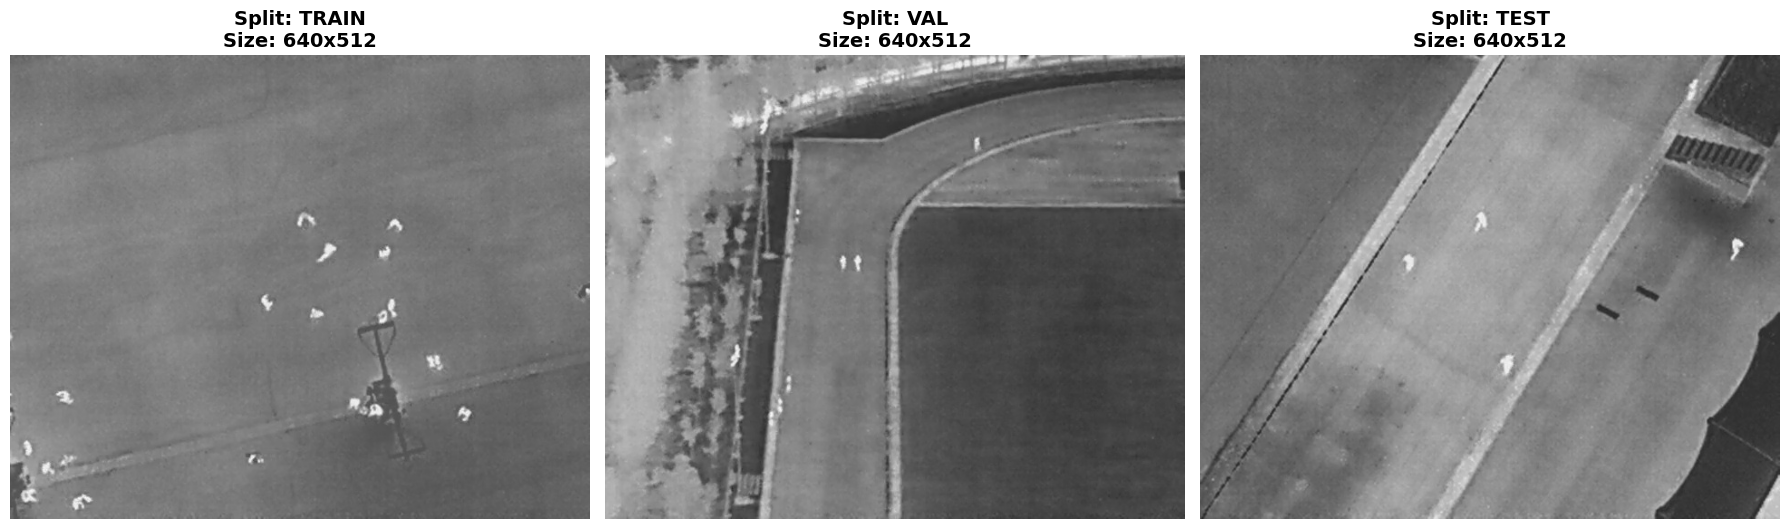

In [ ]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
import random

# مسیر دقیق پوشه تصاویر که در مرحله قبل پیدا کردیم
images_base_path = "/kaggle/input/hituav-a-highaltitude-infrared-thermal-dataset/hit-uav/images"
splits = ['train', 'val', 'test']

# تنظیم سایز نمودار نمایش
plt.figure(figsize=(18, 6))

print("🔍 در حال بررسی سایز و نمایش نمونه تصاویر دیتاست نظامی...\n")

for i, split in enumerate(splits):
    # پیدا کردن تمام عکس‌های داخل پوشه
    search_path = os.path.join(images_base_path, split, "*.*")
    img_files = glob.glob(search_path)

    if len(img_files) > 0:
        # انتخاب یک عکس به صورت تصادفی
        sample_image_path = random.choice(img_files)

        # خواندن عکس با OpenCV
        img = cv2.imread(sample_image_path)

        # تبدیل رنگ از BGR به RGB برای نمایش درست در Matplotlib
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # استخراج ابعاد عکس
        height, width, channels = img.shape
        print(f"✅ پوشه {split.upper()}: سایز عکس برابر است با {width}x{height} پیکسل")

        # رسم عکس
        plt.subplot(1, 3, i + 1)
        plt.imshow(img_rgb)
        plt.title(f"Split: {split.upper()}\nSize: {width}x{height}", fontsize=14, fontweight='bold')
        plt.axis('off')
    else:
        print(f"❌ هیچ عکسی در پوشه {split} پیدا نشد!")

plt.tight_layout()
plt.show()

In [ ]:
# ۴. بارگذاری مدل قدرتمند YOLOv11s
model = YOLO('yolo11s.pt')

In [ ]:
# ۵. شروع آموزش
results = model.train(
    data=config_path,

    # نتایج مستقیم می‌رود به گوگل درایو شما
    project='/content/drive/MyDrive/Thermal_Sentinel',
    name='yolo11_thermal_model',

    epochs=50,
    patience=15,
    imgsz=640,
    batch=16,
    device=0,

    # ⚠️ تنظیمات مخصوص عکس‌های حرارتی ⚠️
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.4,
    mosaic=1.0,
    scale=0.5,
    fliplr=0.5,
)

Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/thermal_dataset_final.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11_thermal_model, nbs=6

In [ ]:
print("🔄 در حال بارگذاری مغزِ آموزش‌دیده (best.pt) برای ادامه مسیر...")
# مسیر بهترین وزنی که در مرحله قبل به دست آوردید
current_best_model = '/content/drive/MyDrive/Thermal_Sentinel/yolo11_thermal_model/weights/best.pt'
config_path = '/content/thermal_dataset_final.yaml'

# بارگذاری مدل از جایی که کارش تمام شده بود
model = YOLO(current_best_model)

print("\n🚀 استارت فاز دوم آموزش (تکمیل ظرفیت مدل برای 20 ایپاک دیگر)...")

# آموزش برای ۲۰ ایپاک اضافه
results = model.train(
    data=config_path,
    project='/content/drive/MyDrive/Thermal_Sentinel',
    name='yolo11_thermal_model_extended', # نام پوشه جدید تا با قبلی قاطی نشود

    epochs=20,           # ۲۰ ایپاکِ تکمیلی
    patience=10,         # اگر در 10 ایپاک پیشرفت نکرد، متوقف شو
    imgsz=640,
    batch=16,
    device=0,

    # ⚠️ حفظ همان شرایط محیطی قبلی ⚠️
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.4,
    mosaic=1.0,
    scale=0.5,
    fliplr=0.5,

    # 💡 ترفند مهندسی: کم کردن نرخ یادگیری (Learning Rate)
    # چون مدل تا حد زیادی پخته شده، نباید با قدم‌های بزرگ یاد بگیرد
    lr0=0.001
)

🔄 در حال بارگذاری مغزِ آموزش‌دیده (best.pt) برای ادامه مسیر...

🚀 استارت فاز دوم آموزش (تکمیل ظرفیت مدل برای 20 ایپاک دیگر)...
Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/thermal_dataset_final.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max